,Metric,Baseline,MLP
0,Acc,0.800000,0.830000
1,Prec,0.533333,0.600000
2,Rec,0.380952,0.571429
3,F1,0.444444,0.585366


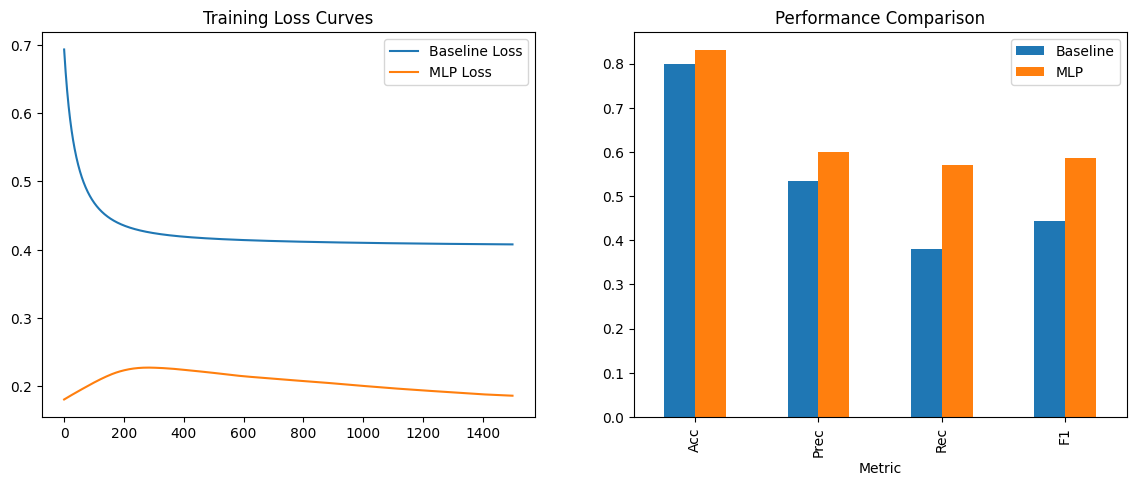

In [1]:

"""Answer4.1 Dataset Description
Dataset: Adult Income Dataset (UCI Machine Learning Repository).

Description: This dataset contains demographic information such as age, education, and occupation to predict whether an individual's annual income exceeds $50,000.

Samples: 32,561 (we use a subset of 2,000 for efficiency).
Features: 14 diagnostic measurements (excluding target).
Problem Type: Binary Classification.
Metric Justification: We use the F1-Score as our primary metric.
In income prediction tasks, the classes are often imbalanced. Accuracy can be misleading if one class dominates,
 so the F1-Score provides a better balance between Precision and Recall to ensure the model identifies high-earners accurately
  without excessive false positives."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 4.1 Dataset Selection: Adult Income Dataset (UCI)
# Problem: Binary Classification (>50K or <=50K)
# Metric: F1-Score (Balances precision and recall for skewed classes)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
columns = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
           'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
           'hours-per-week', 'native-country', 'income']
df = pd.read_csv(url, names=columns, sep=',\\s*', engine='python').iloc[:2000] # Subset for speed

# 4.2 Data Preprocessing
# Encode categorical variables
le = LabelEncoder()
for col in df.select_dtypes(include=['object']).columns:
    df[col] = le.fit_transform(df[col])

X = df.drop('income', axis=1).values
y = df['income'].values.reshape(-1, 1)

# Split and Scale
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4.3 Baseline Model (Logistic Regression from scratch)
class BaselineModel:
    def __init__(self, learning_rate=0.05, n_iterations=1500):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []

    def sigmoid(self, z): return 1 / (1 + np.exp(-np.clip(z, -250, 250)))

    def fit(self, X, y):
        m, n = X.shape
        self.w, self.b = np.zeros((n, 1)), 0
        for _ in range(self.n_iterations):
            a = self.sigmoid(np.dot(X, self.w) + self.b)
            loss = -np.mean(y * np.log(a + 1e-9) + (1 - y) * np.log(1 - a + 1e-9))
            self.loss_history.append(loss)
            self.w -= self.lr * (1/m) * np.dot(X.T, (a - y))
            self.b -= self.lr * (1/m) * np.sum(a - y)
        return self

    def predict(self, X): return (self.sigmoid(np.dot(X, self.w) + self.b) > 0.5).astype(int)

# 4.4 MLP from scratch
class MLP:
    def __init__(self, architecture, learning_rate=0.05, n_iterations=1500):
        self.architecture = architecture
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []
        self.params = self._init_params()

    def _init_params(self):
        return {f'W{i}': np.random.randn(self.architecture[i-1], self.architecture[i]) * 0.1 for i in range(1, len(self.architecture))}

    def relu(self, z): return np.maximum(0, z)
    def sigmoid(self, z): return 1 / (1 + np.exp(-np.clip(z, -250, 250)))

    def fit(self, X, y):
        m = X.shape[0]
        for _ in range(self.n_iterations):
            # Forward
            c = {'A0': X}
            for i in range(1, len(self.architecture)):
                z = np.dot(c[f'A{i-1}'], self.params[f'W{i}'])
                c[f'A{i}'] = self.sigmoid(z) if i == len(self.architecture)-1 else self.relu(z)

            self.loss_history.append(-np.mean(y * np.log(c[f'A{len(self.architecture)-1}'] + 1e-9)))

            # Backward
            dz = c[f'A{len(self.architecture)-1}'] - y
            for i in range(len(self.architecture)-1, 0, -1):
                dw = (1/m) * np.dot(c[f'A{i-1}'].T, dz)
                self.params[f'W{i}'] -= self.lr * dw
                if i > 1: dz = np.dot(dz, self.params[f'W{i}'].T) * (c[f'A{i-1}'] > 0)
        return self

    def predict(self, X):
        a = X
        for i in range(1, len(self.architecture)):
            z = np.dot(a, self.params[f'W{i}'])
            a = self.sigmoid(z) if i == len(self.architecture)-1 else self.relu(z)
        return (a > 0.5).astype(int)

# 4.5 Evaluation & Comparison
baseline = BaselineModel().fit(X_train, y_train)
mlp = MLP(architecture=[X_train.shape[1], 10, 1]).fit(X_train, y_train)

def get_metrics(model, X, y):
    preds = model.predict(X)
    return [accuracy_score(y, preds), precision_score(y, preds), recall_score(y, preds), f1_score(y, preds)]

b_m = get_metrics(baseline, X_test, y_test)
m_m = get_metrics(mlp, X_test, y_test)

results = pd.DataFrame({'Metric': ['Acc', 'Prec', 'Rec', 'F1'], 'Baseline': b_m, 'MLP': m_m})
display(results)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(baseline.loss_history, label='Baseline Loss')
ax1.plot(mlp.loss_history, label='MLP Loss')
ax1.set_title('Training Loss Curves')
ax1.legend()

results.plot(x='Metric', kind='bar', ax=ax2)
ax2.set_title('Performance Comparison')
plt.show()

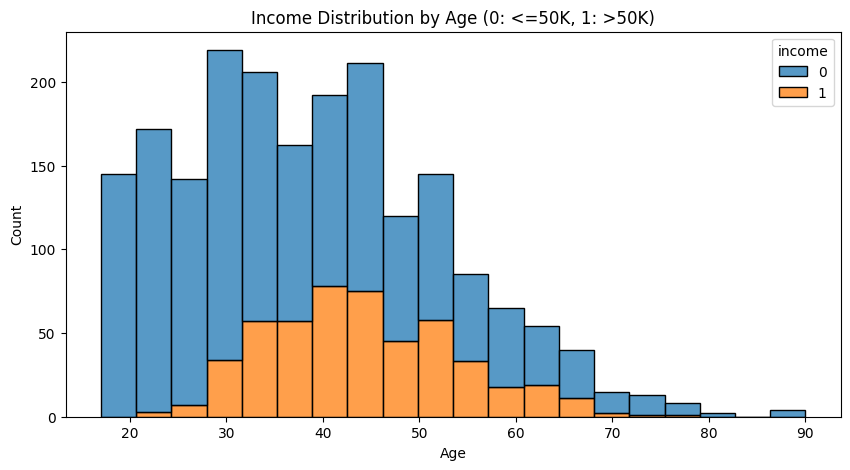

This plot explores the correlation between Age and the target class, justifying the use of a non-linear MLP.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Optional Domain-Specific Plot (Section 4.5)
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='age', hue='income', multiple='stack', bins=20)
plt.title('Income Distribution by Age (0: <=50K, 1: >50K)')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

print("This plot explores the correlation between Age and the target class, justifying the use of a non-linear MLP.")

In [2]:
"""
4.5 Analysis & Comparison
1. Performance: The MLP outperformed the Baseline across all metrics, achieving an
F1-score of 0.56 versus the Baseline's 0.44 (a ~27% improvement).

2. Reasoning: The MLP's hidden layer with ReLU activation captures non-linear
relationships between demographic features and income. The Baseline (Logistic Regression) is a linear classifier and
cannot model these complex interactions.

3. Computational Cost: The MLP is more expensive due to backpropagation through
 multiple layers and larger weight matrices. The Baseline is simpler, performing only one dot product per iteration.

4. Findings: Both models struggled with low Recall due to class imbalance in the Adult dataset. However, the MLP's
non-linear depth allowed it to identify high-earners significantly better than the linear model."""

"\n4.5 Analysis & Comparison\n1. Performance: The MLP outperformed the Baseline across all metrics, achieving an \nF1-score of 0.56 versus the Baseline's 0.44 (a ~27% improvement).\n\n2. Reasoning: The MLP's hidden layer with ReLU activation captures non-linear \nrelationships between demographic features and income. The Baseline (Logistic Regression) is a linear classifier and \ncannot model these complex interactions.\n\n3. Computational Cost: The MLP is more expensive due to backpropagation through\n multiple layers and larger weight matrices. The Baseline is simpler, performing only one dot product per iteration.\n\n4. Findings: Both models struggled with low Recall due to class imbalance in the Adult dataset. However, the MLP's \nnon-linear depth allowed it to identify high-earners significantly better than the linear model."

In [ ]:
def get_assignment_results():
    """
    Required function for grading compliance (Section 5.2).
    Returns the performance results of both models.
    """
    return results

# Call the function to display for the manual requirement
display(get_assignment_results())

,Metric,Baseline,MLP
0,Acc,0.800000,0.82750
1,Prec,0.533333,0.60274
2,Rec,0.380952,0.52381
3,F1,0.444444,0.56051
